In [1]:
RS_GROUP_SERVER = "/home/arsalan/wsu_grid_rs_grp_mljet/"
# RS_GROUP_SERVER = "/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/"

print(RS_GROUP_SERVER)

/home/arsalan/wsu_grid_rs_grp_mljet/


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------
# Paths (EDIT THESE)
# --------------------
OUTPUT_ROOT = Path(RS_GROUP_SERVER+ "pTHat50-250_eCM5020_pTHat50-250_eCM5020_pT90-110_R0p4/")  # root containing .npy event files
METADATA_DIR = OUTPUT_ROOT / "metadata"

# Pick one config to test with (events CSV filename)
CONFIG_NAME = "c0005_alpha0p20_q_1p0_unfolded"
EVENTS_CSV = METADATA_DIR / f"{CONFIG_NAME}_jets.csv"

# Aggregation config
N_AGG = 500          # number of jets to aggregate
MAX_PT = 110.0       # normalization factor per jet
RANDOM_SEED = 0      # for reproducibility

# For plotting extents (if you want φ–η axes)
PHI_RANGE = (-0.5, 0.5)
ETA_RANGE = (-0.5, 0.5)


In [3]:
df_events = pd.read_csv(EVENTS_CSV)
print(f"{CONFIG_NAME}: {len(df_events)} jets total")

if len(df_events) < N_AGG:
    raise ValueError(f"Not enough jets ({len(df_events)}) to sample {N_AGG}.")

# Shuffle and pick N_AGG unique jets
df_sample = df_events.sample(n=N_AGG, random_state=RANDOM_SEED).reset_index(drop=True)
df_sample.head()


c0005_alpha0p20_q_1p0_unfolded: 221933 jets total


,file_paths,alpha,q0,seed,phi_min,phi_max,eta_min,eta_max,pT_min,pT_max
0,c0005_alpha0p20_q_1p0_unfolded/seed_092/event_...,0.2,1.0,92,-0.107596,0.141382,-0.135242,0.210855,0.124772,20.017000
1,c0005_alpha0p20_q_1p0_unfolded/seed_097/event_...,0.2,1.0,97,-0.320715,0.303923,-0.400719,0.377486,0.088028,31.689800
2,c0005_alpha0p20_q_1p0_unfolded/seed_192/event_...,0.2,1.0,192,-0.120055,0.111907,-0.094850,0.202843,0.154541,13.113000
3,c0005_alpha0p20_q_1p0_unfolded/seed_073/event_...,0.2,1.0,73,-0.064156,0.059974,-0.131744,0.039196,0.037018,26.390301
4,c0005_alpha0p20_q_1p0_unfolded/seed_143/event_...,0.2,1.0,143,-0.099626,0.043807,-0.083659,0.257650,0.023933,23.268200


Cell 3 – Load the 500 jet images and normalize by MAX_PT

In [ ]:
# Load all 500 images into memory
imgs = []
for rel_path in df_sample["file_paths"]:
    img_path = OUTPUT_ROOT / rel_path
    arr = np.load(img_path).astype(np.float32)
    imgs.append(arr)

imgs = np.stack(imgs, axis=0)  # shape: (N_AGG, H, W)
print("Stack shape:", imgs.shape)

# Per-jet normalization by fixed MAX_PT
imgs_norm = imgs / MAX_PT


Stack shape: (500, 32, 32)


two more sample from the imgs dataframe with 250 and 125 images respectively.


In [28]:
N_AGG = imgs.shape[0]  # should be 500
rng = np.random.RandomState(RANDOM_SEED)

# 1) Pick 250 images out of the 500
idx_250 = rng.choice(N_AGG, size=250, replace=False)
imgs_250 = imgs[idx_250]               # shape: (250, H, W)
imgs_norm_250 = imgs_250 / MAX_PT
mean_img_250 = imgs_norm_250.mean(axis=0).T  # shape (H, W)

# 2) From those 250, pick 125
idx_125 = rng.choice(250, size=125, replace=False)
imgs_125 = imgs_250[idx_125]           # shape: (125, H, W)
imgs_norm_125 = imgs_125 / MAX_PT
mean_img_125 = imgs_norm_125.mean(axis=0).T  # shape (H, W)

Cell 4 – Compute mean image and log-scaled mean

In [22]:
# Mean over the 500 normalized jets
mean_img = imgs_norm.mean(axis=0).T  # shape (H, W)

# Log scaling; using log1p to avoid log(0)
log_mean_img = np.log1p(mean_img) # natural log of (1 + mean_img)

print("mean_img:     min =", float(mean_img.min()), "max =", float(mean_img.max()))
print("log_mean_img: min =", float(log_mean_img.min()), "max =", float(log_mean_img.max()))


mean_img:     min = 0.0 max = 0.13542743027210236
log_mean_img: min = 0.0 max = 0.12700916826725006


Use the normalized mean image


In [23]:
# Use the normalized mean image
mean_img_masked = np.ma.masked_where(mean_img <= 0, mean_img)
log_mean_img_masked = np.ma.masked_where(log_mean_img <= 0, log_mean_img)

Cell 5 – Visualize (linear vs log)

In [7]:


def log_normalize_image(mean_img, epsilon=1e-8,img_max=None):
    import numpy as np

    I = mean_img
    I_max = float(I.max()) if img_max is None else img_max

    if I_max <= 0:
        # Degenerate case: everything is zero or negative
        I_log = np.zeros_like(I, dtype=np.float32)
    else:
        num = np.log(I + epsilon) - np.log(epsilon)
        den = np.log(I_max + epsilon) - np.log(epsilon)
        I_log = num / den
        # # optional: clip numerical noise
        I_log = np.clip(I_log, 0.0, 1.0)
    return I_log

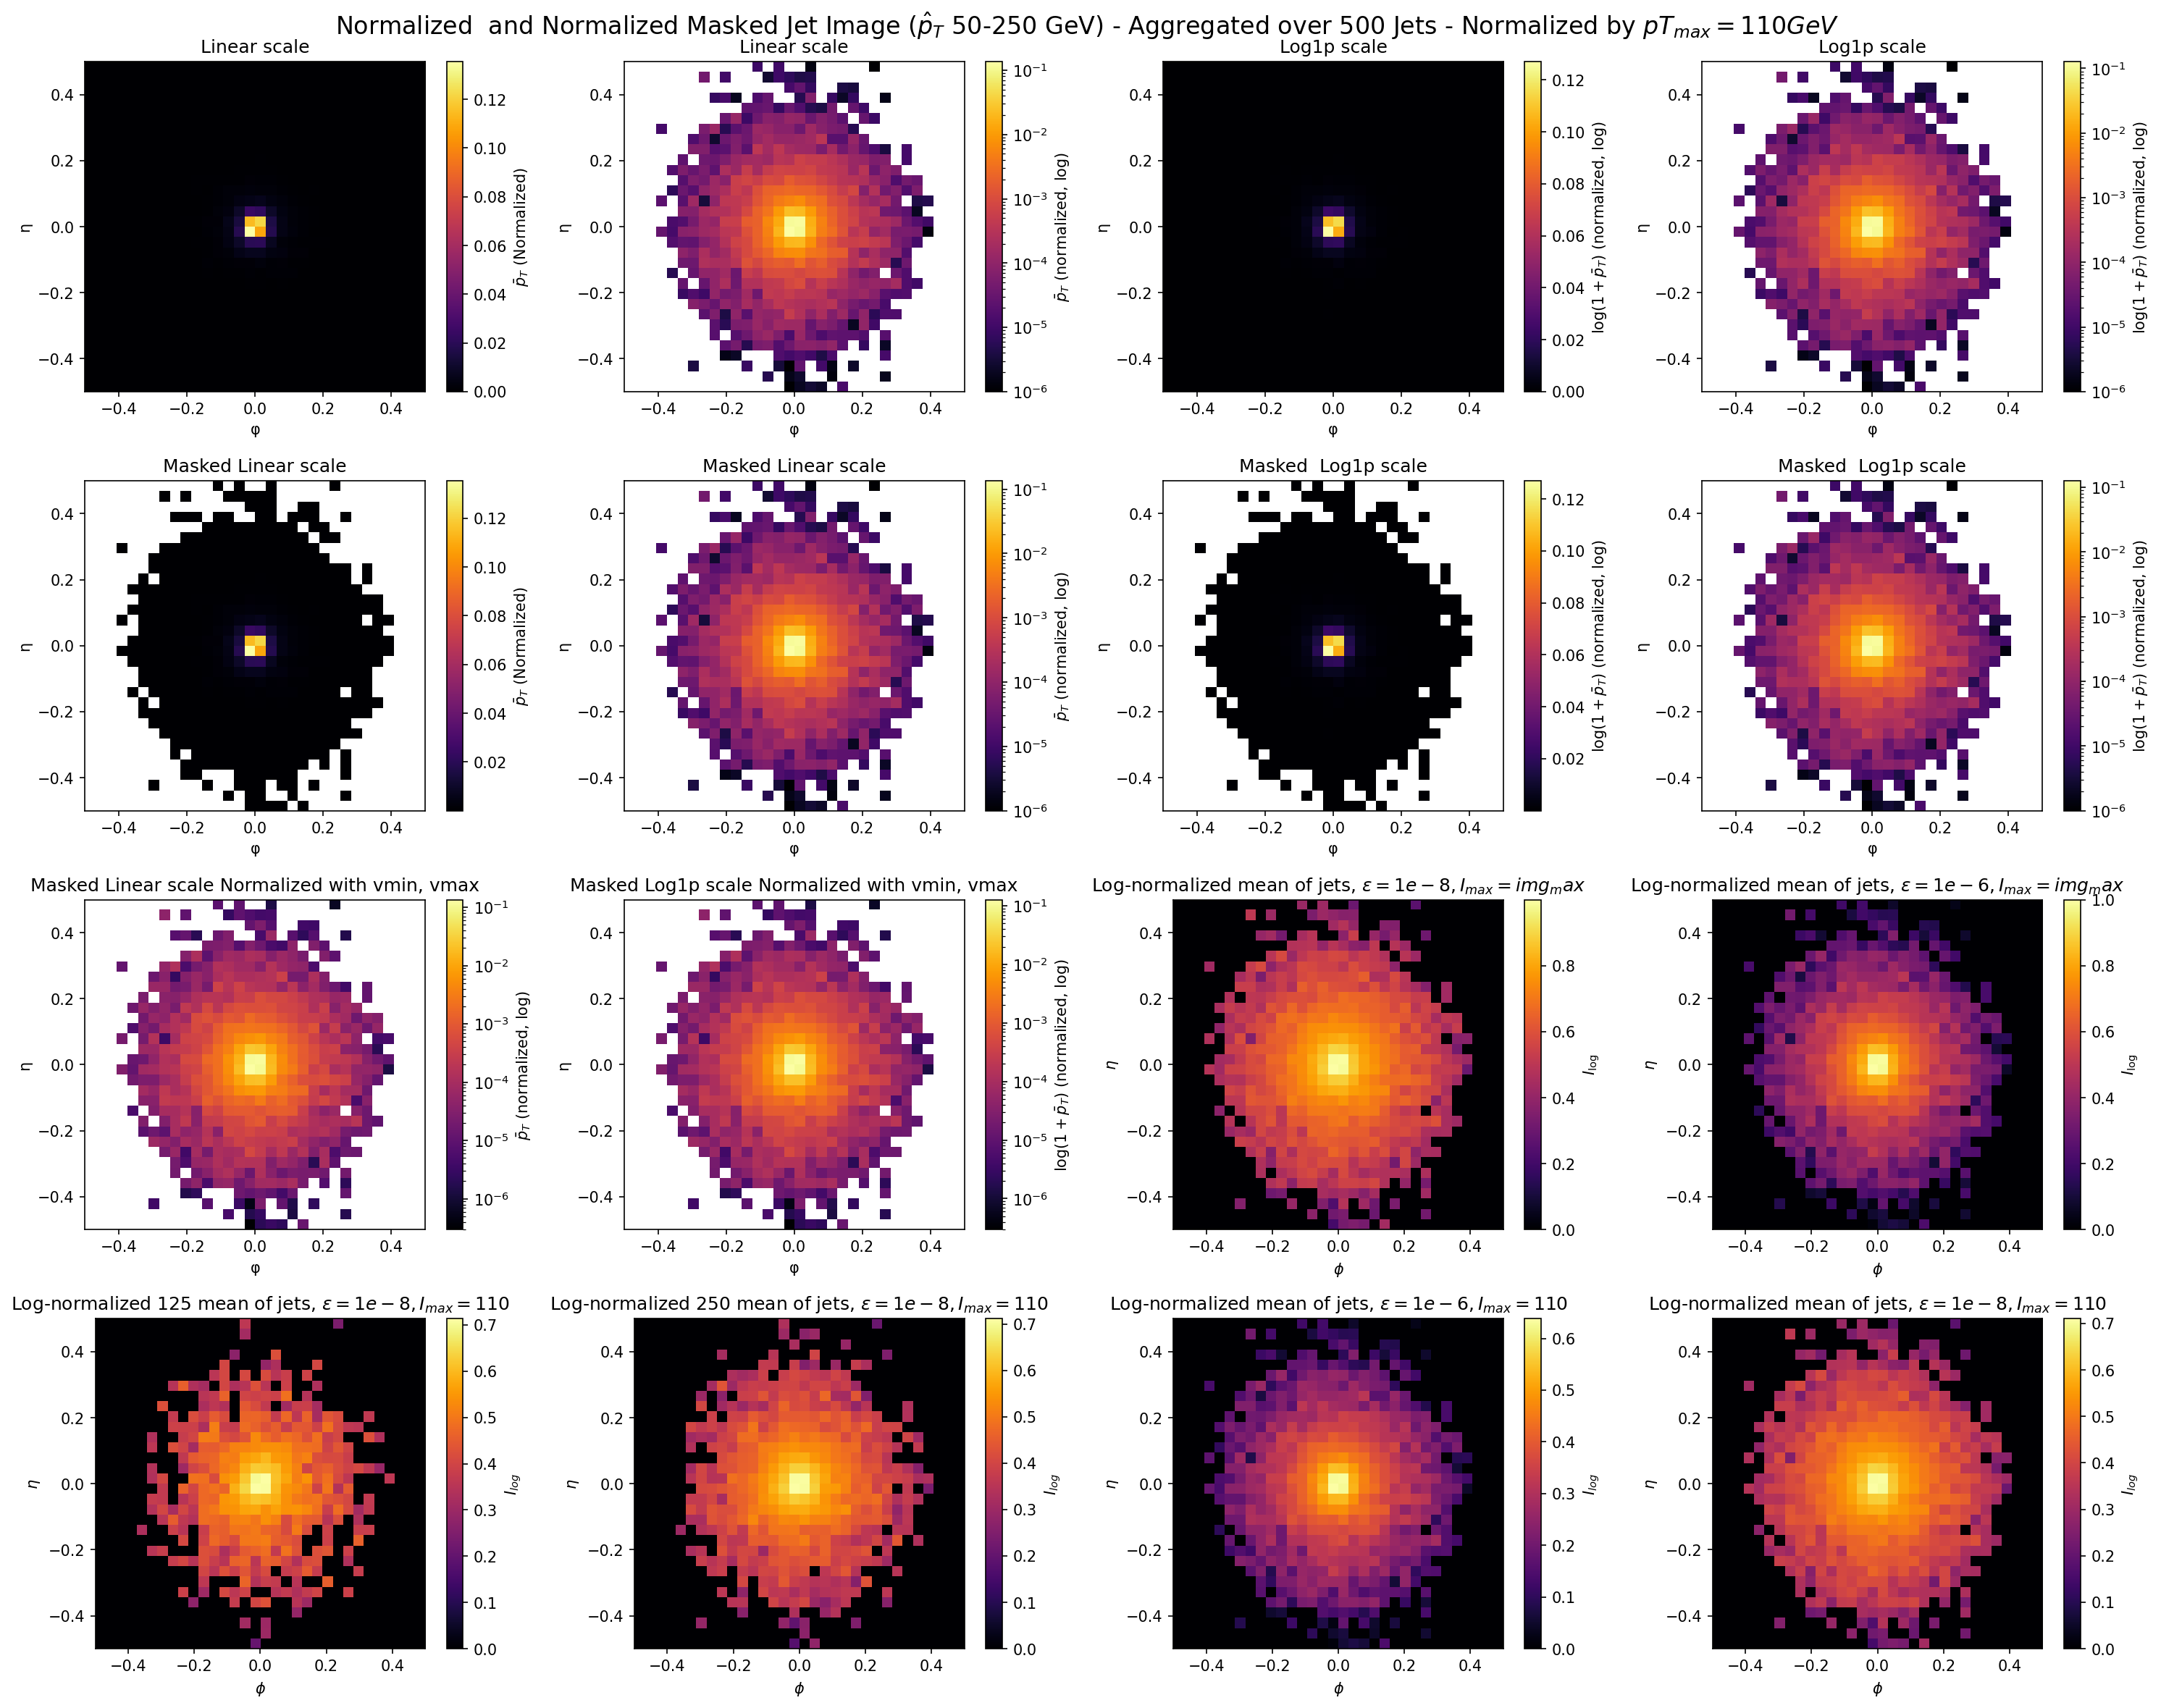

In [ ]:
# let's plot the imgs_norm to see what one of the normalized jets looks like
from matplotlib import colors


data = mean_img  # pick the first jet for visualization
# Plotting extents
phi_min, phi_max = PHI_RANGE
eta_min, eta_max = ETA_RANGE
fig, axes = plt.subplots(4, 4, figsize=(20, 16),dpi=150)
# --- Left: without log normalization (linear) ---
ax = axes[0, 0]
im0 = ax.imshow(
    data,
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    aspect="auto",
    cmap="inferno",
)
ax.set_title("Linear scale")
ax.set_xlabel("φ")
ax.set_ylabel("η")
fig.colorbar(im0, ax=ax, label=r"$\bar{p}_T$ (Normalized)")

# --- middle: with log normalization ---
ax = axes[0, 1]
im1 = ax.imshow(
    data,
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    aspect="auto",
    norm=colors.LogNorm(vmin=1e-6, vmax=data.max()),
    cmap="inferno",
)
ax.set_title("Linear scale")
ax.set_xlabel("φ")
ax.set_ylabel("η")
fig.colorbar(im1, ax=ax, label=r"$\bar{p}_T$ (normalized, log)")

# ---  with log1p  ---
ax = axes[0, 2]
im1 = ax.imshow(
    log_mean_img,
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    aspect="auto",
    cmap="inferno",
)
ax.set_title("Log1p scale")
ax.set_xlabel("φ")
ax.set_ylabel("η")
fig.colorbar(im1, ax=ax, label=r"$\log(1 + \bar{p}_T)$ (normalized, log)")
# ---  with log1p normalization ---
ax = axes[0, 3]
im1 = ax.imshow(
    log_mean_img,
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    aspect="auto",
    norm=colors.LogNorm(vmin=1e-6, vmax=log_mean_img.max()),
    cmap="inferno",
)
ax.set_title("Log1p scale")
ax.set_xlabel("φ")
ax.set_ylabel("η")
fig.colorbar(im1, ax=ax, label=r"$\log(1 + \bar{p}_T)$ (normalized, log)")

# --- Left: without log normalization (linear) ---
ax = axes[1, 0]
im0 = ax.imshow(
    mean_img_masked,
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    aspect="auto",
    cmap="inferno",
)
ax.set_title("Masked Linear scale")
ax.set_xlabel("φ")
ax.set_ylabel("η")
fig.colorbar(im0, ax=ax, label=r"$\bar{p}_T$ (Normalized)")

# --- middle: with log normalization ---
ax = axes[1, 1]
im1 = ax.imshow(
    mean_img_masked,
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    aspect="auto",
    norm=colors.LogNorm(vmin=1e-6, vmax=mean_img_masked.max()),
    cmap="inferno",
)
ax.set_title("Masked Linear scale")
ax.set_xlabel("φ")
ax.set_ylabel("η")
fig.colorbar(im1, ax=ax, label=r"$\bar{p}_T$ (normalized, log)")

# ---  with log1p  ---
ax = axes[1, 2]
im1 = ax.imshow(
    log_mean_img_masked,
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    aspect="auto",
    cmap="inferno",
)
ax.set_title("Masked  Log1p scale")
ax.set_xlabel("φ")
ax.set_ylabel("η")
fig.colorbar(im1, ax=ax, label=r"$\log(1 + \bar{p}_T)$ (normalized, log)")
# ---  with log1p normalization ---
ax = axes[1, 3]
im1 = ax.imshow(
    log_mean_img_masked,
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    aspect="auto",
    norm=colors.LogNorm(vmin=1e-6, vmax=log_mean_img_masked.max()),
    cmap="inferno",
)
ax.set_title("Masked  Log1p scale")
ax.set_xlabel("φ")
ax.set_ylabel("η")
fig.colorbar(im1, ax=ax, label=r"$\log(1 + \bar{p}_T)$ (normalized, log)")



vmin_log = float(mean_img_masked[mean_img_masked > 0].min())
vmax_log = float(mean_img_masked.max())
# --- middle: with log normalization ---
ax = axes[2, 0]
im1 = ax.imshow(
    mean_img_masked,
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    aspect="auto",
    norm=colors.LogNorm(vmin=vmin_log, vmax=vmax_log),
    cmap="inferno",
)
ax.set_title("Masked Linear scale Normalized with vmin, vmax")
ax.set_xlabel("φ")
ax.set_ylabel("η")
fig.colorbar(im1, ax=ax, label=r"$\bar{p}_T$ (normalized, log)")


vmin_log = float(log_mean_img_masked[log_mean_img_masked > 0].min())
vmax_log = float(log_mean_img_masked.max())
# ---  with log1p normalization ---
ax = axes[2, 1]
im1 = ax.imshow(
    log_mean_img_masked,
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    aspect="auto",
    norm=colors.LogNorm(vmin=vmin_log, vmax=vmax_log),
    cmap="inferno",
)
ax.set_title("Masked Log1p scale Normalized with vmin, vmax")
ax.set_xlabel("φ")
ax.set_ylabel("η")
fig.colorbar(im1, ax=ax, label=r"$\log(1 + \bar{p}_T)$ (normalized, log)")

ax = axes[2, 2]
iml=ax.imshow(
    log_normalize_image(mean_img,epsilon=1e-8),                # transpose if you want (phi, eta) orientation
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    # aspect="auto",
    cmap="inferno",
    # interpolation="nearest",
)

ax.set_title(r"Log-normalized mean of jets, $\epsilon=1e-8, I_{max}=img_max$")
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\eta$")
fig.colorbar(iml, ax=ax, label=r"$I_{\log}$")

ax = axes[2, 3]
iml=ax.imshow(
    log_normalize_image(mean_img,epsilon=1e-6),                # transpose if you want (phi, eta) orientation
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    # aspect="auto",
    cmap="inferno",
    # interpolation="nearest",
)

ax.set_title(r"Log-normalized mean of jets, $\epsilon=1e-6, I_{max}=img_max$")
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\eta$")
fig.colorbar(iml, ax=ax, label=r"$I_{\log}$")


ax = axes[3, 0]
iml=ax.imshow(
    log_normalize_image(mean_img_125,epsilon=1e-8,img_max=110),                # transpose if you want (phi, eta) orientation
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    # aspect="auto",
    cmap="inferno",
    # interpolation="nearest",
)

ax.set_title(r"Log-normalized 125 mean of jets, $\epsilon=1e-8, I_{max}=110$")
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\eta$")
fig.colorbar(iml, ax=ax, label=r"$I_{\log}$")

ax = axes[3, 1]
iml=ax.imshow(
    log_normalize_image(mean_img_250,epsilon=1e-8,img_max=110),                # transpose if you want (phi, eta) orientation
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    # aspect="auto",
    cmap="inferno",
    # interpolation="nearest",
)

ax.set_title(r"Log-normalized 250 mean of jets, $\epsilon=1e-8, I_{max}=110$")
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\eta$")
fig.colorbar(iml, ax=ax, label=r"$I_{\log}$")


ax = axes[3, 2]
iml=ax.imshow(
    log_normalize_image(mean_img,epsilon=1e-6,img_max=110),                # transpose if you want (phi, eta) orientation
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    # aspect="auto",
    cmap="inferno",
    # interpolation="nearest",
)

ax.set_title(r"Log-normalized mean of jets, $\epsilon=1e-6, I_{max}=110$")
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\eta$")
fig.colorbar(iml, ax=ax, label=r"$I_{\log}$")

ax = axes[3, 3]
iml=ax.imshow(
    log_normalize_image(mean_img,epsilon=1e-8,img_max=110),                # transpose if you want (phi, eta) orientation
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    # aspect="auto",
    cmap="inferno",
    # interpolation="nearest",
)

ax.set_title(r"Log-normalized mean of jets, $\epsilon=1e-8, I_{max}=110$")
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\eta$")
fig.colorbar(iml, ax=ax, label=r"$I_{\log}$")

plt.suptitle(r"Normalized  and Normalized Masked Jet Image (${\hat{p}_T}$ 50-250 GeV) - Aggregated over 500 Jets - Normalized by $pT_{max}=110GeV$", fontsize=16)
plt.tight_layout()

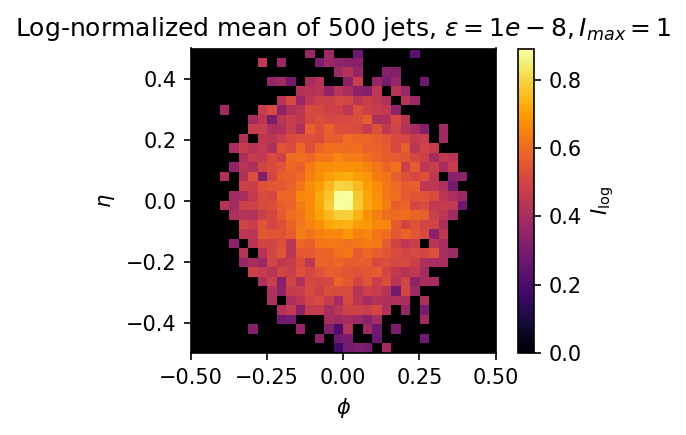

In [44]:
import matplotlib.pyplot as plt

phi_min, phi_max = PHI_RANGE
eta_min, eta_max = ETA_RANGE

plt.figure(figsize=(4, 3), dpi=150)
plt.imshow(
    log_normalize_image(mean_img,epsilon=1e-8,img_max=1),                # transpose if you want (phi, eta) orientation
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    # aspect="auto",
    cmap="inferno",
    # interpolation="nearest",
)

plt.title(r"Log-normalized mean of 500 jets, $\epsilon=1e-8, I_{max}=1$")
plt.xlabel(r"$\phi$")
plt.ylabel(r"$\eta$")
plt.colorbar(label=r"$I_{\log}$")
plt.tight_layout()
plt.show()
